# Marketing Campaign Performance: Exploratory Data Analysis

**Goal:** understand how advertising drives user acquisition and engagement, and tell the story the data contains.

**Dataset:** [Marketing Campaign Performance (Kaggle)](https://www.kaggle.com/datasets/manishabhatt22/marketing-campaign-performance-dataset)

**Key questions**
1. Which channels acquire users most efficiently (CTR, conversion rate, cost per conversion, ROI)?
2. Do more impressions or higher spend translate into more engagement?
3. Which customer segments, audiences, countries and languages respond best?
4. Does campaign duration affect ROI or engagement?
5. Is there seasonality or a trend over time?
6. Which combinations of channel, campaign type and audience perform best, and which waste budget?

**Limitations:** the dataset looks synthetic and has no retention data. `Engagement_Score` is the closest proxy.

## 1. Setup and data loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# The notebook lives in notebooks/, so the data folder is one level up
df = pd.read_csv("../data/marketing_campaign_dataset.csv")

## 2. First inspection

Goal: understand the structure before changing anything (size, column types, nulls, duplicates, value ranges).

In [3]:
# Display the information about the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Campaign_ID       200000 non-null  int64  
 1   Company           200000 non-null  str    
 2   Campaign_Type     200000 non-null  str    
 3   Target_Audience   200000 non-null  str    
 4   Duration          200000 non-null  str    
 5   Channel_Used      200000 non-null  str    
 6   Conversion_Rate   200000 non-null  float64
 7   Acquisition_Cost  200000 non-null  str    
 8   ROI               200000 non-null  float64
 9   Location          200000 non-null  str    
 10  Language          200000 non-null  str    
 11  Clicks            200000 non-null  int64  
 12  Impressions       200000 non-null  int64  
 13  Engagement_Score  200000 non-null  int64  
 14  Customer_Segment  200000 non-null  str    
 15  Date              200000 non-null  str    
dtypes: float64(2), int64(4), str(10

In [4]:
# Display the first few rows of the DataFrame
df.head()

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


In [5]:
# Describes the dataset to get a statistical summary of the numerical columns
df.describe()

,Campaign_ID,Conversion_Rate,ROI,Clicks,Impressions,Engagement_Score
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,100000.500000,0.080070,5.002438,549.772030,5507.301520,5.494710
std,57735.171256,0.040602,1.734488,260.019056,2596.864286,2.872581
min,1.000000,0.010000,2.000000,100.000000,1000.000000,1.000000
25%,50000.750000,0.050000,3.500000,325.000000,3266.000000,3.000000
50%,100000.500000,0.080000,5.010000,550.000000,5517.500000,5.000000
75%,150000.250000,0.120000,6.510000,775.000000,7753.000000,8.000000
max,200000.000000,0.150000,8.000000,1000.000000,10000.000000,10.000000


In [6]:
# Check for null values in the dataset
print(f"Number of null values per column:\n{df.isnull().sum()}")

Number of null values per column:
Campaign_ID         0
Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Conversion_Rate     0
Acquisition_Cost    0
ROI                 0
Location            0
Language            0
Clicks              0
Impressions         0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64


In [7]:
# Check for duplicated rows in the dataset
print(f"Number of duplicated rows:\n{df.duplicated().sum()}")

Number of duplicated rows:
0


In [8]:
# Check if the column Campaign_ID has unique values
print(f"Does column Campaign_ID has unique values?\n{df['Campaign_ID'].is_unique}")

Does column Campaign_ID has unique values?
True


**What the numerical summary and quality checks tell us**

- **No missing values and no duplicates.** All 16 columns have 200,000 non-null values, there are 0 duplicated rows and every `Campaign_ID` is unique (1 to 200,000). No rows need to be dropped or imputed.
- **All numerical ranges are plausible:**
  - `Conversion_Rate` goes from 0.01 to 0.15 (1% to 15%), with a mean of 0.08.
  - `ROI` goes from 2.00 to 8.00, with a mean of 5.00. There are no negative values, so no campaign in the dataset loses money.
  - `Clicks` goes from 100 to 1,000 and `Impressions` from 1,000 to 10,000.
  - `Engagement_Score` is a 1 to 10 scale, with a mean of 5.49.
- **The values look evenly spread.** In every column the mean is very close to the median, and the quartiles are spaced almost equally between the minimum and the maximum. This is typical of randomly generated data and fits the idea that the dataset is synthetic.
- **`Acquisition_Cost` is missing from this summary** because it is stored as text ("$16,174.00"). It will be converted to a number in the cleaning step.

In [9]:
# Check if any row has more clicks than impressions
print(f"Rows with more clicks than impressions:\n{(df['Clicks'] > df['Impressions']).sum()}")

Rows with more clicks than impressions:
0


**Clicks vs impressions:** there are 0 rows with more clicks than impressions, so this inconsistency does not appear in the data. This matches the ranges in `describe()`: the maximum number of clicks (1,000) equals the minimum number of impressions (1,000), so clicks can never exceed impressions.

In [10]:
# Categorical columns to analyze
# There are 10 text columns, but Acquisition_Cost (a number) and Date (a date) are not categories,
# so only the remaining 8 are kept
columns = df.select_dtypes(include="str").columns
to_exclude = ["Acquisition_Cost", "Date"]
analysis_columns = [col for col in columns if col not in to_exclude]

print(f"Categorical columns to analyze:\n{analysis_columns}")

Categorical columns to analyze:
['Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Location', 'Language', 'Customer_Segment']


In [11]:
# Number of distinct values per categorical column
df[analysis_columns].nunique()

Company             5
Campaign_Type       5
Target_Audience     5
Duration            4
Channel_Used        6
Location            5
Language            5
Customer_Segment    5
dtype: int64

In [12]:
# Show the values and their frequency for each categorical column
for col in analysis_columns:
    print(f"--- {col} ---")         # name of the column as a header
    print(df[col].value_counts())   # show the frequency of each value
    print()                         # print a blank line for better readability

--- Company ---
Company
TechCorp               40237
Alpha Innovations      40051
DataTech Solutions     40012
NexGen Systems         39991
Innovate Industries    39709
Name: count, dtype: int64

--- Campaign_Type ---
Campaign_Type
Influencer      40169
Search          40157
Display         39987
Email           39870
Social Media    39817
Name: count, dtype: int64

--- Target_Audience ---
Target_Audience
Men 18-24      40258
Men 25-34      40023
All Ages       40019
Women 25-34    40013
Women 35-44    39687
Name: count, dtype: int64

--- Duration ---
Duration
30 days    50255
45 days    50100
60 days    49866
15 days    49779
Name: count, dtype: int64

--- Channel_Used ---


Channel_Used
Email         33599
Google Ads    33438
YouTube       33392
Instagram     33392
Website       33360
Facebook      32819
Name: count, dtype: int64

--- Location ---
Location
Miami          40269
New York       40024
Chicago        40010
Los Angeles    39947
Houston        39750
Name: count, dtype: int64

--- Language ---
Language
Mandarin    40255
Spanish     40102
German      39983
English     39896
French      39764
Name: count, dtype: int64

--- Customer_Segment ---
Customer_Segment
Foodies                40208
Tech Enthusiasts       40151
Outdoor Adventurers    40011
Health & Wellness      39888
Fashionistas           39742
Name: count, dtype: int64



**What the categorical columns tell us**

- **No typos or inconsistent labels.** Every column has a small, clean set of values (4 to 6), with no value written in two different ways. No text cleaning is needed for these columns.
- **Categories are almost perfectly balanced.** Columns with 5 values have about 40,000 rows per category (for example, `Company` ranges from 39,709 to 40,237). `Channel_Used` has 6 channels with about 33,000 rows each (32,819 to 33,599), and `Duration` has 4 values with about 50,000 each (49,779 to 50,255). Such an even split is unusual in real marketing data and is another sign that the dataset is synthetic. It also suggests that differences between groups will likely be small.
- **`Duration` only takes 4 values:** 15, 30, 45 and 60 days. It is stored as text ("30 days"). In the cleaning step it will be converted to an integer and renamed `Duration_days`, so the unit is clear from the column name.
- **`Location` contains 5 US cities**, not countries (Miami, New York, Chicago, Los Angeles, Houston), while `Language` includes Mandarin, Spanish, German, English and French. Location-based conclusions will be about cities, not countries.

## 3. Data cleaning and preprocessing

### 3.1 Fixing column types

The first inspection showed that the data has no missing values, no duplicates and no inconsistent labels. The only problems are **three columns stored with the wrong type**:

| Column | Problem | Decision |
|---|---|---|
| `Acquisition_Cost` | Text with a dollar sign and commas (`"$16,174.00"`), so it cannot be used in calculations | Remove `$` and `,` and convert to float (USD) |
| `Duration` | Text with the unit inside the value (`"30 days"`) | Keep only the number, convert to integer and rename to `Duration_days` so the unit is in the column name |
| `Date` | Text (`"2021-01-01"`), so it cannot be used for time analysis | Convert to datetime |

**Why the cleaning code is in `src/cleaning.py` and not in this notebook:** the same cleaning steps are reused by the notebook and by the data pipeline, so they are written once as functions. Each function has tests in `tests/test_cleaning.py` that were written before the function itself, checking for example that `"$16,174.00"` becomes `16174.0`. To run them, use `pytest` from the repo root.

In [13]:
import sys

# The notebook runs from notebooks/, so add the repo root to the path to import src/
sys.path.append("..")
from src.cleaning import clean_campaigns

# Keep the raw data in df and work on a cleaned copy
df_clean = clean_campaigns(df)
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Campaign_ID       200000 non-null  int64         
 1   Company           200000 non-null  str           
 2   Campaign_Type     200000 non-null  str           
 3   Target_Audience   200000 non-null  str           
 4   Duration_days     200000 non-null  int64         
 5   Channel_Used      200000 non-null  str           
 6   Conversion_Rate   200000 non-null  float64       
 7   Acquisition_Cost  200000 non-null  float64       
 8   ROI               200000 non-null  float64       
 9   Location          200000 non-null  str           
 10  Language          200000 non-null  str           
 11  Clicks            200000 non-null  int64         
 12  Impressions       200000 non-null  int64         
 13  Engagement_Score  200000 non-null  int64         
 14  Customer_Segmen

In [14]:
# Compare the same rows before and after cleaning
print("Before cleaning:")
print(df[["Acquisition_Cost", "Duration", "Date"]].head(3))
print("\nAfter cleaning:")
print(df_clean[["Acquisition_Cost", "Duration_days", "Date"]].head(3))

Before cleaning:
  Acquisition_Cost Duration        Date
0       $16,174.00  30 days  2021-01-01
1       $11,566.00  60 days  2021-01-02
2       $10,200.00  30 days  2021-01-03

After cleaning:
   Acquisition_Cost  Duration_days       Date
0           16174.0             30 2021-01-01
1           11566.0             60 2021-01-02
2           10200.0             30 2021-01-03


In [15]:
# Check the new columns: value ranges and date coverage
print(df_clean[["Acquisition_Cost", "Duration_days"]].describe())
print(f"\nDate range: {df_clean['Date'].min().date()} to {df_clean['Date'].max().date()}")
print(f"Distinct dates: {df_clean['Date'].nunique()}")

       Acquisition_Cost  Duration_days
count     200000.000000  200000.000000
mean       12504.393040      37.503975
std         4337.664545      16.746720
min         5000.000000      15.000000
25%         8739.750000      30.000000
50%        12496.500000      30.000000
75%        16264.000000      45.000000
max        20000.000000      60.000000

Date range: 2021-01-01 to 2021-12-31
Distinct dates: 365


**What the cleaning changed**

- **All conversions worked on every row.** `df_clean` still has 200,000 rows and 0 missing values, so no value failed to convert. The row-by-row comparison shows that `"$16,174.00"` became `16174.0`, `"30 days"` became `30` and the dates kept the same value with a datetime type.
- **`Acquisition_Cost` goes from 5,000 to 20,000 USD**, with a mean of 12,504 USD. Like the other numerical columns, the mean is very close to the median (12,496.50), which again points to evenly spread, generated data.
- **`Duration_days`** now holds the 4 numeric values 15, 30, 45 and 60, so it can be used in calculations and correlations.
- **`Date` covers the full year 2021** (2021-01-01 to 2021-12-31) with all 365 days present. Since there are 200,000 campaigns, each date has many campaigns, which makes monthly or weekly trends possible.
- **The raw data is kept in `df`** and all the analysis from here uses `df_clean`. This way the original values are always available to compare.

### 3.2 Derived metrics (feature engineering)

The dataset gives raw counts and rates, but the key questions are about **efficiency**, so new metrics are needed. The dataset does not define two of its columns, so these **assumptions** are made:

- `Conversion_Rate` is **conversions / clicks**, the usual marketing definition.
- `Acquisition_Cost` is the **total spend of the campaign** in USD. Its range (5,000 to 20,000 USD) fits a campaign budget, not a cost per customer.

| New column | Formula | What it measures |
|---|---|---|
| `CTR` | Clicks / Impressions | How attractive the ad is |
| `Conversions` | Clicks × Conversion_Rate | Estimated customers acquired |
| `CPC` | Acquisition_Cost / Clicks | Cost per click (USD) |
| `Cost_per_Conversion` | Acquisition_Cost / Conversions | Cost per acquired customer (USD), the main efficiency metric |
| `CPM` | Acquisition_Cost / Impressions × 1,000 | Cost per 1,000 impressions (USD). Normalizes reach cost so campaigns of different sizes can be compared fairly |
| `Month`, `Weekday` | From `Date` | Used for seasonality |

The functions are in `src/features.py` and tested in `tests/test_features.py`. The tests use one row with easy numbers (500 clicks, 2,000 impressions, 10% conversion, 10,000 USD) so every expected result can be checked by hand.

In [16]:
from src.features import add_features

df_clean = add_features(df_clean)
df_clean[["Clicks", "Impressions", "Conversion_Rate", "Acquisition_Cost",
          "CTR", "Conversions", "CPC", "Cost_per_Conversion", "CPM", "Month", "Weekday"]].head()

,Clicks,Impressions,Conversion_Rate,Acquisition_Cost,CTR,Conversions,CPC,Cost_per_Conversion,CPM,Month,Weekday
0,506,1922,0.04,16174.0,0.263267,20.24,31.964427,799.110672,8415.192508,1,Friday
1,116,7523,0.12,11566.0,0.015419,13.92,99.706897,830.890805,1537.418583,1,Saturday
2,584,7698,0.07,10200.0,0.075864,40.88,17.465753,249.510763,1325.019486,1,Sunday
3,217,1820,0.11,12724.0,0.119231,23.87,58.635945,533.054043,6991.208791,1,Monday
4,379,4201,0.05,16452.0,0.090217,18.95,43.408971,868.179420,3916.210426,1,Tuesday


In [17]:
# Summary of the new metrics, and how many campaigns have an unrealistic CTR
new_metrics = ["CTR", "Conversions", "CPC", "Cost_per_Conversion", "CPM"]
print(df_clean[new_metrics].describe().round(3))

high_ctr = (df_clean["CTR"] > 0.5).sum()
print(f"\nCampaigns with CTR above 50%: {high_ctr} ({high_ctr / len(df_clean):.1%})")

              CTR  Conversions         CPC  Cost_per_Conversion         CPM
count  200000.000   200000.000  200000.000           200000.000  200000.000
mean        0.140       44.023      32.008              635.329    3193.943
std         0.131       32.317      26.926              970.140    2698.980
min         0.010        1.000       5.021               34.218     501.401
25%         0.059       17.760      15.092              180.484    1508.453
50%         0.100       35.760      22.774              334.396    2269.956
75%         0.170       64.100      38.599              692.481    3837.796
max         0.992      150.000     199.960            19432.353   19896.104

Campaigns with CTR above 50%: 6166 (3.1%)


**What the new metrics tell us**

- **The metrics are correct but their scale is not realistic.** The median CTR is 10.0% and 6,166 campaigns (3.1%) have a CTR above 50%, while real ad CTRs are usually a few percent. The median CPM is 2,270 USD, while real CPMs are usually tens of dollars. This is a **data quality limitation of the synthetic dataset**: comparisons *between* groups are still valid, but absolute values should not be read as real-world benchmarks.
- **A typical campaign gets about 36 conversions** (median) at a cost of **334 USD per conversion**.
- **`Cost_per_Conversion` is strongly right-skewed**: the mean (635 USD) is almost twice the median (334 USD) and the maximum reaches 19,432 USD. A few campaigns with very few conversions make the average misleading. For this reason, the analysis will compare groups using the **median**, and a **log scale** will be used when plotting this metric.
- These extreme values are checked as outliers in the next step.

### 3.3 Outliers (IQR rule)

An outlier is a value far from the rest. The **IQR rule** defines "far" in a simple, standard way:

- **IQR** (interquartile range) = Q3 − Q1, the width of the middle 50% of the data.
- A value is an outlier if it is **below Q1 − 1.5 × IQR** or **above Q3 + 1.5 × IQR**.

The functions `iqr_bounds` and `flag_outliers_iqr` are in `src/quality.py` and tested in `tests/test_quality.py`. Here they are applied to every numerical column, original and derived.

In [18]:
from src.quality import flag_outliers_iqr, iqr_bounds

# Count outliers in every numerical column, original and derived
numeric_cols = ["Conversion_Rate", "ROI", "Acquisition_Cost", "Clicks", "Impressions",
                "Engagement_Score", "CTR", "Conversions", "CPC", "Cost_per_Conversion", "CPM"]

rows = []
for col in numeric_cols:
    low, high = iqr_bounds(df_clean[col])
    n_outliers = flag_outliers_iqr(df_clean[col]).sum()
    rows.append({"column": col, "lower_limit": low, "upper_limit": high,
                 "outliers": n_outliers, "outliers_pct": n_outliers / len(df_clean) * 100})

outlier_summary = pd.DataFrame(rows).set_index("column").round(2)
outlier_summary

,lower_limit,upper_limit,outliers,outliers_pct
column,,,,
Conversion_Rate,-0.05,0.22,0,0.00
ROI,-1.01,11.02,0,0.00
Acquisition_Cost,-2546.62,27550.38,0,0.00
Clicks,-350.00,1450.00,0,0.00
Impressions,-3464.50,14483.50,0,0.00
Engagement_Score,-4.50,15.50,0,0.00
CTR,-0.11,0.34,16141,8.07
Conversions,-51.75,133.61,1563,0.78
CPC,-20.17,73.86,16044,8.02


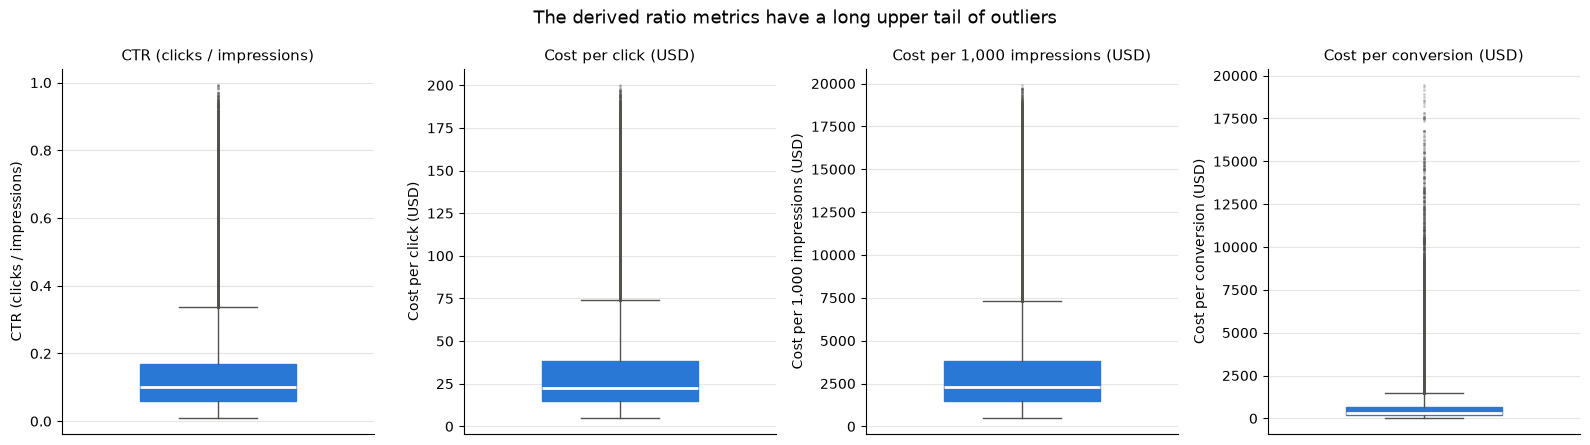

In [19]:
# Boxplots of the four metrics with outliers, one panel each because their scales differ
plot_metrics = {
    "CTR": "CTR (clicks / impressions)",
    "CPC": "Cost per click (USD)",
    "CPM": "Cost per 1,000 impressions (USD)",
    "Cost_per_Conversion": "Cost per conversion (USD)",
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, plot_metrics.items()):
    ax.boxplot(
        df_clean[col],
        widths=0.5,
        patch_artist=True,
        boxprops={"facecolor": "#2a78d6", "color": "#2a78d6"},
        medianprops={"color": "white", "linewidth": 2},
        whiskerprops={"color": "#52514e"},
        capprops={"color": "#52514e"},
        flierprops={"marker": "o", "markersize": 2, "markerfacecolor": "#52514e",
                    "markeredgecolor": "none", "alpha": 0.3},
    )
    ax.set_title(label, fontsize=11)
    ax.set_ylabel(label)
    ax.set_xticks([])
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle("The derived ratio metrics have a long upper tail of outliers", fontsize=13)
plt.tight_layout()
plt.show()

**What the outlier check tells us**

- **The original columns have no outliers at all.** `Conversion_Rate`, `ROI`, `Acquisition_Cost`, `Clicks`, `Impressions` and `Engagement_Score` all have 0 values outside the IQR limits. Their values are spread evenly between a fixed minimum and maximum, so there are no extreme cases.
- **Outliers only appear in the derived ratio metrics**, about 8% to 9% of the campaigns for `CTR`, `CPC`, `CPM` and `Cost_per_Conversion`. Dividing one evenly spread column by another produces a long right tail: when the denominator is small (few impressions, few clicks or few conversions), the ratio becomes very large. The boxplots show this long upper tail.
- **Decision: keep all outliers and flag them.** They are not data errors. They are campaigns where the cost was spread over very few results, which is exactly what question 6 (budget waste) needs to find. Removing them would hide the most inefficient campaigns.

In [20]:
# Flag the high-cost campaigns (kept in the data) and compare them with the rest
df_clean["High_Cost_Outlier"] = flag_outliers_iqr(df_clean["Cost_per_Conversion"])

compare_cols = ["Cost_per_Conversion", "Conversions", "Clicks", "Conversion_Rate",
                "Acquisition_Cost", "ROI", "Engagement_Score"]
comparison = df_clean.groupby("High_Cost_Outlier")[compare_cols].median().round(2)
comparison.index = ["Normal campaigns", "High-cost outliers"]
comparison

,Cost_per_Conversion,Conversions,Clicks,Conversion_Rate,Acquisition_Cost,ROI,Engagement_Score
Normal campaigns,298.29,39.80,582.0,0.09,12156.0,5.01,5.0
High-cost outliers,2229.12,6.14,232.0,0.02,15444.0,5.00,5.0


**Who are the high-cost outliers?**

The 18,445 campaigns flagged in `High_Cost_Outlier` (9.2%) are kept in the data and compared with the rest using medians:

- **They pay about 7 times more per customer**: 2,229 USD per conversion vs 298 USD for normal campaigns.
- **The cause is low results, not only high spend.** They get far fewer clicks (232 vs 582), a much lower conversion rate (2% vs 9%) and therefore only about 6 conversions vs 40. Their spend is also higher (15,444 vs 12,156 USD), which makes the cost per conversion even worse.
- **Their ROI is the same as normal campaigns (5.00 vs 5.01)**, and so is their engagement (5 vs 5). In real data, a campaign that pays 7 times more per customer should have a much lower ROI. This shows that **the `ROI` column is not consistent with the cost and conversion columns**, so ROI cannot be trusted alone to judge efficiency. The analysis will use `Cost_per_Conversion` as the main efficiency metric and report ROI separately, with this limitation stated.

### 3.4 Second data source: US public holidays (API + merge)

To check whether campaigns behave differently on holidays (question 5, seasonality), the data is enriched with the **US public holidays of 2021** from the free [Nager.Date API](https://date.nager.at), downloaded with `requests`.

Decisions:

- **Only federal holidays are kept** (`"global": true` in the API). The 5 cities are in 5 different states (New York, California, Illinois, Texas and Florida), so state-only holidays do not apply to all of them.
- **One row per date.** The API returns some dates more than once (for example 11 October appears 3 times). If the holiday table had a repeated date, the merge would **duplicate** every campaign of that day, so duplicates are dropped first.
- **Left merge on `Date`**, so every campaign is kept exactly once, and campaigns on normal days get `Is_Holiday = False`.
- **Local cache.** The first run downloads the holidays and saves them to `data/us_holidays_2021.csv`. Later runs read that file, so the notebook also works offline and always uses the same data.

Each campaign has a single `Date`, which is read here as its **start date**.

In [21]:
from src.holidays import load_us_holidays

# Downloads from the API with requests the first time, then reads the saved CSV
holidays = load_us_holidays(2021, "../data/us_holidays_2021.csv")
holidays

,Date,Holiday_Name
0,2021-01-01,New Year's Day
1,2021-01-18,"Martin Luther King, Jr. Day"
2,2021-02-15,Presidents Day
3,2021-05-31,Memorial Day
4,2021-06-18,Juneteenth National Independence Day
5,2021-07-05,Independence Day
6,2021-09-06,Labour Day
7,2021-10-11,Columbus Day
8,2021-11-11,Veterans Day
9,2021-11-25,Thanksgiving Day


In [22]:
from src.holidays import add_holiday_flag

# Left merge on Date: every campaign is kept, holiday columns are added
rows_before = len(df_clean)
df_clean = add_holiday_flag(df_clean, holidays)

print(f"Rows before merge: {rows_before:,} | after merge: {len(df_clean):,}")
print(f"Campaigns that started on a federal holiday: {df_clean['Is_Holiday'].sum():,} "
      f"({df_clean['Is_Holiday'].mean():.1%})")
df_clean.loc[df_clean["Is_Holiday"], "Holiday_Name"].value_counts()

Rows before merge: 200,000 | after merge: 200,000
Campaigns that started on a federal holiday: 6,027 (3.0%)


Holiday_Name
New Year's Day                          548
Martin Luther King, Jr. Day             548
Presidents Day                          548
Memorial Day                            548
Juneteenth National Independence Day    548
Independence Day                        548
Labour Day                              548
Columbus Day                            548
Veterans Day                            548
Thanksgiving Day                        548
Christmas Day                           547
Name: count, dtype: int64

In [23]:
# Check how dates are assigned: campaigns per date, and whether the date
# simply follows the campaign ID in a 365-day rotation
campaigns_per_date = df_clean["Date"].value_counts()
print(f"Campaigns per date: min {campaigns_per_date.min()}, max {campaigns_per_date.max()}")

rotation_date = pd.Timestamp("2021-01-01") + pd.to_timedelta((df_clean["Campaign_ID"] - 1) % 365, unit="D")
print(f"Rows where Date = 1 Jan + (Campaign_ID - 1) mod 365 days: {(df_clean['Date'] == rotation_date).mean():.1%}")

Campaigns per date: min 547, max 548
Rows where Date = 1 Jan + (Campaign_ID - 1) mod 365 days: 100.0%


**What the merge tells us**

- **The merge worked as intended**: 200,000 rows before and after, so no campaign was duplicated or lost.
- **The API returned 11 federal holidays for 2021.** Two of them are *observed* dates: Independence Day appears on 5 July and Christmas Day on 24 December, because 4 July 2021 was a Sunday and 25 December 2021 was a Saturday.
- **6,027 campaigns (3.0%) started on a federal holiday**, with 547 or 548 campaigns on each holiday.
- **Data quality finding: dates are assigned in a fixed rotation.** Every date has exactly 547 or 548 campaigns, and checking the IDs shows that campaign 1 starts on 1 January, campaign 2 on 2 January and so on, starting over every 365 campaigns. This holds for 100% of the rows. In other words, **the date depends only on the campaign ID**, not on any business decision. Real campaigns would cluster around key periods (Black Friday, Christmas, summer). This means **seasonality and holiday effects cannot really exist in this dataset**. Question 5 will still be checked, but a flat result is the expected outcome and will be reported as such.

### 3.5 Reproducible pipeline

All the steps of this section (type fixes, derived metrics, outlier flag and holiday merge) are also chained in `src/pipeline.py`, using the same tested functions. From the repo root, one command rebuilds the processed dataset:

```bash
python -m src.pipeline
```

It saves `data/processed/campaigns_clean.csv` (200,000 rows, 26 columns). The file is not committed to the repo because it can always be regenerated from the raw CSV.

## 4. Exploratory analysis

Each subsection answers one key question with a summary table, a chart and a short reading. Two rules apply to all of them, based on what the cleaning showed:

- **Groups are compared with medians**, not means, because the cost metrics are strongly skewed.
- **Every comparison is checked with a statistical test.** The dataset is synthetic and its groups are almost identical in size, so small differences between medians can be pure noise. The **Kruskal-Wallis test** (`src/significance.py`, tested in `tests/test_significance.py`) tells whether the groups really differ:
  - **p-value < 0.05** means the difference is unlikely to be chance.
  - **Effect size (ε²)** says how much the grouping matters: around 0.01 is small, 0.08 moderate, 0.26 large. With 200,000 rows, a tiny difference can be "significant" but irrelevant, so both numbers are needed.

Kruskal-Wallis is used instead of ANOVA because it compares ranks, not raw values, so it does not need normally distributed data and outliers do not distort it.

### 4.1 Which channels acquire customers most efficiently?

Efficiency is measured at every step of the funnel: attracting clicks (`CTR`), turning clicks into customers (`Conversion_Rate`) and the cost of each customer (`Cost_per_Conversion`, the main metric), plus `CPC`, `CPM`, `ROI` and `Engagement_Score`. `High_Cost_Share` is the share of each channel's campaigns flagged as high-cost outliers in section 3.3.

In [24]:
# Median of each efficiency metric per channel, plus volume and share of high-cost campaigns
channel_summary = df_clean.groupby("Channel_Used").agg(
    Campaigns=("Campaign_ID", "count"),
    CTR=("CTR", "median"),
    Conversion_Rate=("Conversion_Rate", "median"),
    Cost_per_Conversion=("Cost_per_Conversion", "median"),
    CPC=("CPC", "median"),
    CPM=("CPM", "median"),
    ROI=("ROI", "median"),
    Engagement_Score=("Engagement_Score", "median"),
    High_Cost_Share=("High_Cost_Outlier", "mean"),
).sort_values("Cost_per_Conversion")

channel_summary.round({"CTR": 4, "Conversion_Rate": 2, "Cost_per_Conversion": 1, "CPC": 2,
                       "CPM": 0, "ROI": 3, "High_Cost_Share": 4})

,Campaigns,CTR,Conversion_Rate,Cost_per_Conversion,CPC,CPM,ROI,Engagement_Score,High_Cost_Share
Channel_Used,,,,,,,,,
Website,33360,0.1001,0.08,330.5,22.68,2272.0,5.030,6.0,0.0915
Email,33599,0.1001,0.08,331.2,22.79,2270.0,5.000,5.0,0.0906
Google Ads,33438,0.0991,0.08,334.3,22.73,2257.0,5.010,5.0,0.0947
Facebook,32819,0.0999,0.08,336.4,22.84,2278.0,5.040,6.0,0.0920
YouTube,33392,0.0998,0.08,337.0,22.71,2265.0,4.970,6.0,0.0919
Instagram,33392,0.0998,0.08,337.3,22.93,2276.0,4.985,5.0,0.0927


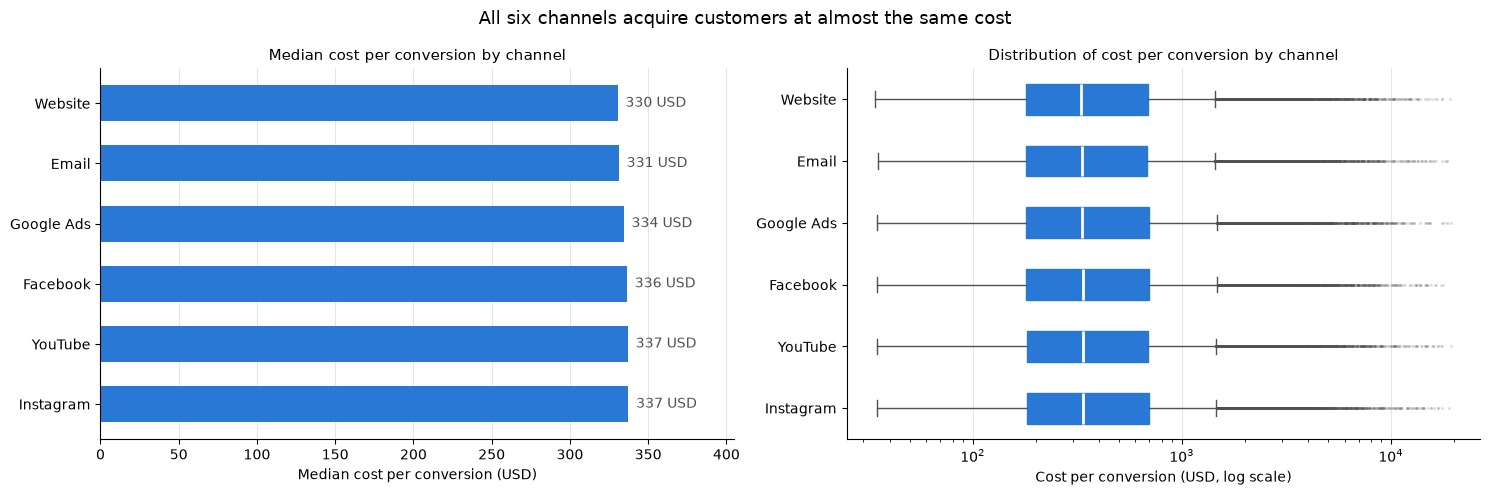

In [25]:
BLUE = "#2a78d6"    # main color for single-series charts
GRAY = "#52514e"    # secondary ink for whiskers, labels and outliers
GRID = "#e5e5e2"

# Horizontal charts draw the first item at the bottom, so sort descending to put the cheapest on top
channel_order = channel_summary.sort_values("Cost_per_Conversion", ascending=False).index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Left: median cost per conversion, axis starting at 0 so differences are not exaggerated
medians = channel_summary.loc[channel_order, "Cost_per_Conversion"]
ax1.barh(channel_order, medians, color=BLUE, height=0.6)
for y, value in enumerate(medians):
    ax1.text(value + 5, y, f"{value:,.0f} USD", va="center", color=GRAY, fontsize=10)
ax1.set_xlim(0, medians.max() * 1.2)
ax1.set_xlabel("Median cost per conversion (USD)")
ax1.set_title("Median cost per conversion by channel", fontsize=11)

# Right: full distribution on a log scale, because the metric is strongly skewed
data = [df_clean.loc[df_clean["Channel_Used"] == ch, "Cost_per_Conversion"] for ch in channel_order]
ax2.boxplot(
    data, orientation="horizontal", tick_labels=channel_order, widths=0.5, patch_artist=True,
    boxprops={"facecolor": BLUE, "color": BLUE},
    medianprops={"color": "white", "linewidth": 2},
    whiskerprops={"color": GRAY}, capprops={"color": GRAY},
    flierprops={"marker": "o", "markersize": 2, "markerfacecolor": GRAY,
                "markeredgecolor": "none", "alpha": 0.2},
)
ax2.set_xscale("log")
ax2.set_xlabel("Cost per conversion (USD, log scale)")
ax2.set_title("Distribution of cost per conversion by channel", fontsize=11)

for ax in (ax1, ax2):
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle("All six channels acquire customers at almost the same cost", fontsize=13)
plt.tight_layout()
fig.savefig("../reports/figures/q1_channels_cost_per_conversion.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
from src.significance import compare_groups

# Do the channels really differ? One Kruskal-Wallis test per metric
efficiency_metrics = ["CTR", "Conversion_Rate", "Cost_per_Conversion", "CPC", "CPM", "ROI", "Engagement_Score"]
channel_tests = compare_groups(df_clean, "Channel_Used", efficiency_metrics)
channel_tests.round({"H": 2, "p_value": 3, "epsilon_squared": 6})

,H,p_value,epsilon_squared,significant
metric,,,,
CTR,5.42,0.367,0.000002,False
Conversion_Rate,2.90,0.715,0.000000,False
Cost_per_Conversion,5.96,0.310,0.000005,False
CPC,3.80,0.578,0.000000,False
CPM,1.32,0.933,0.000000,False
ROI,7.72,0.172,0.000014,False
Engagement_Score,1.85,0.870,0.000000,False


**Answer to question 1: no channel acquires customers more efficiently than the others.**

- **The medians are almost identical.** Median cost per conversion goes from 330.5 USD (Website) to 337.3 USD (Instagram), a gap of under 7 USD (about 2%). CTR is 9.9% to 10.0% in every channel, conversion rate is 8% in all of them, and median ROI goes from 4.97 to 5.04.
- **The full distributions overlap completely.** On the log-scale boxplots, the boxes, whiskers and outlier tails of the six channels are the same. The share of high-cost campaigns is also similar everywhere (9.1% to 9.5%).
- **The statistical test confirms it is noise.** No metric shows a significant difference between channels: all p-values are between 0.17 and 0.93, well above 0.05, and the effect size ε² is practically 0 (at most 0.000014). The ranking in the table would change with a different sample.
- **The engagement medians of 5 vs 6** look like a difference, but `Engagement_Score` is a whole number from 1 to 10, so the median jumps from one integer to the next. The test (p = 0.87) shows the channels do not differ.

**What it means for the business:** in this data, *choosing a channel* is not a lever to cut acquisition costs. The difference between a good and a bad campaign happens **inside** each channel (section 3.3 found 9.2% high-cost campaigns spread evenly across all of them), so budget decisions should look at campaign-level results rather than at the channel.

### 4.2 Do more spend or more impressions lead to more engagement?

A **correlation** measures how two variables move together, from −1 (when one goes up, the other goes down) through 0 (no relationship) to +1 (they go up together). The **Spearman** correlation is used instead of the usual Pearson correlation because, like Kruskal-Wallis, it works with ranks: it does not assume a straight-line relationship and is not distorted by the skewed cost metrics.

**Reading the matrix correctly:** some derived metrics are calculated from others (for example `Conversions = Clicks × Conversion_Rate` and `Cost_per_Conversion = Acquisition_Cost / Conversions`). Those pairs correlate **by construction**, not because of any real effect, so they are not findings. The relationships that matter are between the **original, independent columns**: spend, impressions, clicks, ROI, engagement and duration.

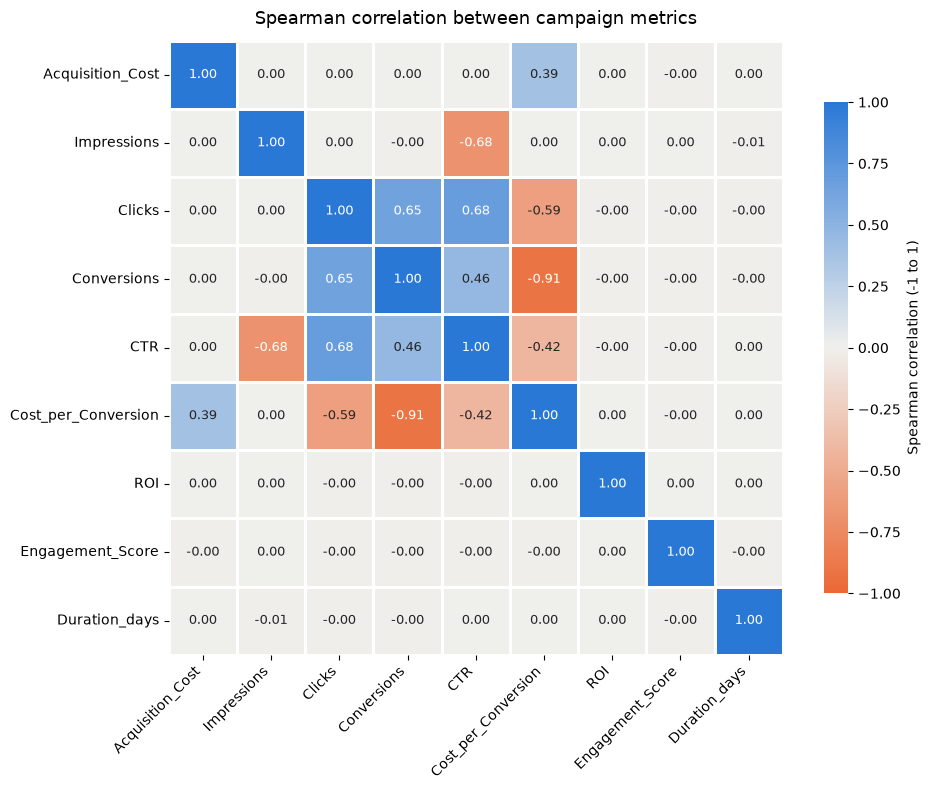

Acquisition_Cost   -0.003
Impressions         0.003
Clicks             -0.002
Conversions        -0.001
Name: Engagement_Score, dtype: float64

In [27]:
from matplotlib.colors import LinearSegmentedColormap

corr_cols = ["Acquisition_Cost", "Impressions", "Clicks", "Conversions", "CTR",
             "Cost_per_Conversion", "ROI", "Engagement_Score", "Duration_days"]
corr = df_clean[corr_cols].corr(method="spearman")

# Diverging palette: orange for negative, neutral gray at 0, blue for positive
diverging = LinearSegmentedColormap.from_list("orange_gray_blue", ["#eb6834", "#f0efec", "#2a78d6"])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, vmin=-1, vmax=1, cmap=diverging, annot=True, fmt=".2f", annot_kws={"size": 9},
    square=True, linewidths=2, linecolor="white",
    cbar_kws={"label": "Spearman correlation (-1 to 1)", "shrink": 0.8}, ax=ax,
)
ax.set_title("Spearman correlation between campaign metrics", fontsize=13, pad=12)
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
fig.savefig("../reports/figures/q2_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# The row this question is about
corr.loc[["Acquisition_Cost", "Impressions", "Clicks", "Conversions"], "Engagement_Score"].round(3)

**What the correlation matrix tells us**

- **Engagement is not related to anything.** Its correlation with spend (−0.003), impressions (0.003), clicks (−0.002) and conversions (−0.001) is practically 0. The same is true for ROI and duration: their whole rows are 0.00.
- **All original columns are independent of each other.** Spend, impressions, clicks, ROI, engagement and duration have correlations between −0.01 and 0.01 among themselves. In real campaigns, a bigger budget usually buys more impressions and clicks. Here it does not (spend vs impressions = 0.00), which confirms the columns were generated separately.
- **The colored cells are mechanical, not findings.** Every strong correlation involves a derived metric and its own ingredients: `Conversions` with `Cost_per_Conversion` (−0.91), `Clicks` and `Impressions` with `CTR` (+0.68 and −0.68), `Clicks` with `Conversions` (+0.65), `Acquisition_Cost` with `Cost_per_Conversion` (+0.39). They only show the formulas from section 3.2 working as expected.
- **One useful reading from these pairs:** cost per conversion depends much more on **how many conversions** a campaign gets (−0.91) than on **how much it spends** (+0.39). This matches the outlier profile in section 3.3: expensive customers come from campaigns that convert poorly, not mainly from big budgets.

In [28]:
def tier_summary(data, column, unit):
    """Split `column` into 5 equal-size tiers (quintiles) and summarize engagement per tier."""
    tiers = pd.qcut(data[column], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
    table = data.groupby(tiers, observed=True).agg(
        Min=(column, "min"), Max=(column, "max"),
        Campaigns=("Campaign_ID", "count"),
        Mean_Engagement=("Engagement_Score", "mean"),
    )
    table["Tier_Label"] = [f"{name}\n{lo:,.0f}-{hi:,.0f} {unit}" for name, lo, hi
                           in zip(table.index, table["Min"], table["Max"])]
    return table, tiers


spend_tiers, spend_tier_col = tier_summary(df_clean, "Acquisition_Cost", "USD")
impression_tiers, impression_tier_col = tier_summary(df_clean, "Impressions", "impr.")

# Kruskal-Wallis: does engagement differ between tiers?
tier_tests = pd.concat([
    compare_groups(df_clean.assign(Tier=spend_tier_col), "Tier", ["Engagement_Score"]).rename(index={"Engagement_Score": "by spend tier"}),
    compare_groups(df_clean.assign(Tier=impression_tier_col), "Tier", ["Engagement_Score"]).rename(index={"Engagement_Score": "by impression tier"}),
])

print("Engagement by spend tier:")
print(spend_tiers.drop(columns="Tier_Label").round(3))
print("\nEngagement by impression tier:")
print(impression_tiers.drop(columns="Tier_Label").round(3))
print("\nKruskal-Wallis test on engagement:")
print(tier_tests.round({"H": 2, "p_value": 3, "epsilon_squared": 6}))

Engagement by spend tier:
                      Min      Max  Campaigns  Mean_Engagement
Acquisition_Cost                                              
Q1 (lowest)        5000.0   7999.0      40012            5.494
Q2                 8000.0  10992.0      40005            5.518
Q3                10993.0  14010.0      39990            5.499
Q4                14011.0  17013.0      39994            5.487
Q5 (highest)      17014.0  20000.0      39999            5.476

Engagement by impression tier:
               Min    Max  Campaigns  Mean_Engagement
Impressions                                          
Q1 (lowest)   1000   2811      40015            5.481
Q2            2812   4617      39991            5.479
Q3            4618   6401      39999            5.511
Q4            6402   8200      40025            5.501
Q5 (highest)  8201  10000      39970            5.502

Kruskal-Wallis test on engagement:
                       H  p_value  epsilon_squared  significant
metric                 

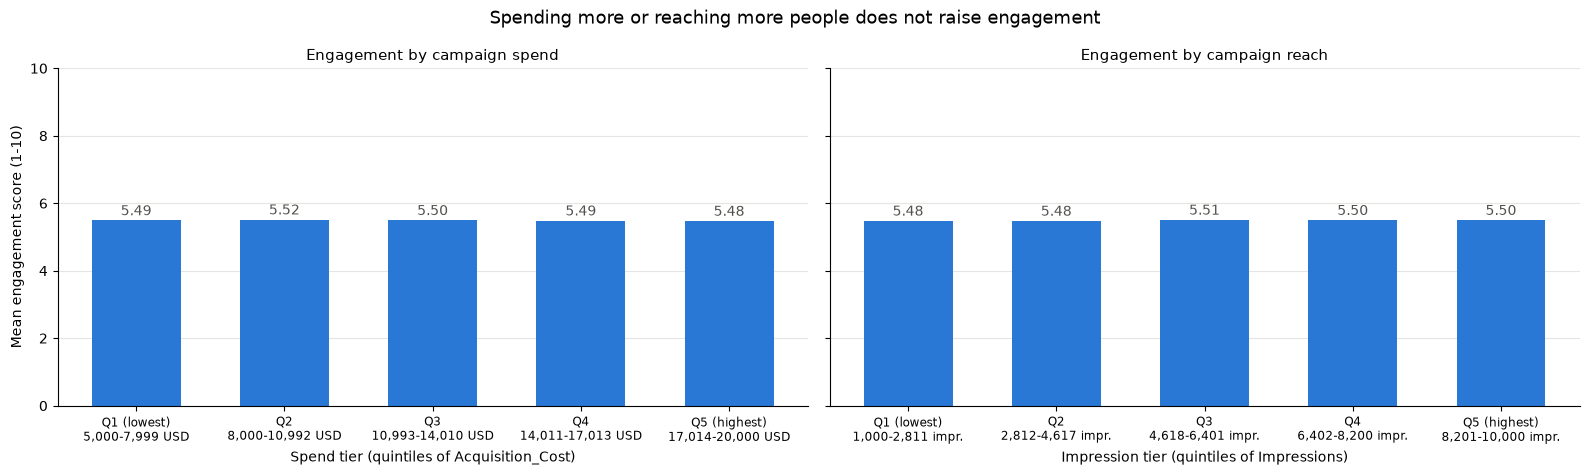

In [29]:
# Mean engagement per spend tier and per impression tier, on the full 1-10 scale
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
panels = [
    (spend_tiers, "Spend tier (quintiles of Acquisition_Cost)", "Engagement by campaign spend"),
    (impression_tiers, "Impression tier (quintiles of Impressions)", "Engagement by campaign reach"),
]
for ax, (table, xlabel, title) in zip(axes, panels):
    ax.bar(table["Tier_Label"], table["Mean_Engagement"], color=BLUE, width=0.6)
    for x, value in enumerate(table["Mean_Engagement"]):
        ax.text(x, value + 0.15, f"{value:.2f}", ha="center", color=GRAY, fontsize=10)
    ax.set_ylim(0, 10)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelsize=8.5)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Mean engagement score (1-10)")

fig.suptitle("Spending more or reaching more people does not raise engagement", fontsize=13)
plt.tight_layout()
fig.savefig("../reports/figures/q2_engagement_by_spend_and_reach.png", dpi=150, bbox_inches="tight")
plt.show()

**Answer to question 2: no. More spend or more impressions do not lead to more engagement.**

- **Engagement is flat across every tier.** Campaigns are split into 5 equal groups (quintiles) by spend and by impressions. Mean engagement stays between 5.48 and 5.52 in every group, both for the cheapest campaigns (5,000 to 7,999 USD) and for the most expensive ones (17,014 to 20,000 USD), and both for the smallest reach (1,000 to 2,811 impressions) and the largest (8,201 to 10,000).
- **The test confirms it.** Kruskal-Wallis gives p = 0.337 for spend tiers and p = 0.438 for impression tiers, with an effect size of practically 0.
- **Mean instead of median here:** `Engagement_Score` only takes the values 1 to 10, so its median can only jump between whole numbers and hides small changes. The mean shows the trend more precisely and, because the scale is bounded, it is not distorted by outliers.

**What it means for the business:** in this dataset, raising the budget or buying more impressions does not buy better engagement. Doubling or quadrupling spend leaves engagement where it was, so extra budget should be justified by more conversions, not by an expected gain in engagement. Because the dataset has no retention data and `Engagement_Score` is the closest proxy, this also means there is **no evidence that bigger campaigns produce more loyal users**.

### 4.3 Which customer segments, audiences, cities and languages respond best?

Four dimensions describe *who* a campaign targets: `Customer_Segment` (interests), `Target_Audience` (gender and age), `Location` (5 US cities, not countries, as noted in section 2) and `Language`. Each one is compared on the same metrics as the channels: CTR, conversion rate, cost per conversion, ROI and engagement.

**Many tests at once.** This section runs 4 dimensions × 5 metrics = **20 tests**. With a threshold of p < 0.05, each test has a 5% chance of looking significant by pure chance, so across 20 tests about **one false positive is expected** even when nothing is real. This is the *multiple comparisons problem*. The simplest fix is the **Bonferroni correction**: divide the threshold by the number of tests (0.05 / 20 = 0.0025). Both results are shown.

In [30]:
dimensions = {
    "Customer_Segment": "Customer segment",
    "Target_Audience": "Target audience",
    "Location": "City",
    "Language": "Language",
}

# Same summary for every dimension, stacked into one table (Dimension, Group)
audience_summary = pd.concat(
    {
        dimension: df_clean.groupby(dimension).agg(
            Campaigns=("Campaign_ID", "count"),
            CTR=("CTR", "median"),
            Conversion_Rate=("Conversion_Rate", "median"),
            Cost_per_Conversion=("Cost_per_Conversion", "median"),
            ROI=("ROI", "median"),
            Mean_Engagement=("Engagement_Score", "mean"),
            High_Cost_Share=("High_Cost_Outlier", "mean"),
        )
        for dimension in dimensions
    },
    names=["Dimension", "Group"],
)

audience_summary.round({"CTR": 4, "Conversion_Rate": 2, "Cost_per_Conversion": 1,
                        "ROI": 2, "Mean_Engagement": 2, "High_Cost_Share": 4})

Campaigns     CTR  Conversion_Rate  \
Dimension        Group                                                     
Customer_Segment Fashionistas             39742  0.0996             0.08   
                 Foodies                  40208  0.1002             0.08   
                 Health & Wellness        39888  0.0992             0.08   
                 Outdoor Adventurers      40011  0.1000             0.08   
                 Tech Enthusiasts         40151  0.1001             0.08   
Target_Audience  All Ages                 40019  0.0997             0.08   
                 Men 18-24                40258  0.0998             0.08   
                 Men 25-34                40023  0.1000             0.08   
                 Women 25-34              40013  0.0998             0.08   
                 Women 35-44              39687  0.0996             0.08   
Location         Chicago                  40010  0.0999             0.08   
                 Houston                  39750  0.0997             0.08   
                 Los Angeles              39947  0.0999             0.08   
                 Miami                    40269  0.0998             0.08   
                 New York                 40024  0.0998             0.08   
Language         English                  39896  0.1000             0.08   
                 French                   39764  0.1002             0.08   
                 German                   39983  0.0995             0.08   
                 Mandarin                 40255  0.0995             0.08   
                 Spanish                  40102  0.0998             0.08   

                                      Cost_per_Conversion   ROI  \
Dimension        Group                                            
Customer_Segment Fashionistas                       335.5  5.00   
                 Foodies                            331.5  5.02   
                 Health & Wellness                  335.1  5.01   
                 Outdoor Adventurers                335.0  5.00   
                 Tech Enthusiasts                   334.5  5.00   
Target_Audience  All Ages                           335.5  5.01   
                 Men 18-24                          334.5  4.99   
                 Men 25-34                          334.8  5.02   
                 Women 25-34                        333.6  4.99   
                 Women 35-44                        333.7  5.01   
Location         Chicago                            334.2  5.01   
                 Houston                            333.2  5.00   
                 Los Angeles                        337.4  5.02   
                 Miami                              335.0  5.02   
                 New York                           331.8  4.99   
Language         English                            332.4  4.99   
                 French                             333.7  5.02   
                 German                             334.6  4.99   
                 Mandarin                           335.5  5.01   
                 Spanish                            335.4  5.01   

                                      Mean_Engagement  High_Cost_Share  
Dimension        Group                                                  
Customer_Segment Fashionistas                    5.49           0.0919  
                 Foodies                         5.51           0.0939  
                 Health & Wellness               5.48           0.0927  
                 Outdoor Adventurers             5.50           0.0923  
                 Tech Enthusiasts                5.49           0.0903  
Target_Audience  All Ages                        5.49           0.0929  
                 Men 18-24                       5.52           0.0912  
                 Men 25-34                       5.49           0.0910  
                 Women 25-34                     5.49           0.0929  
                 Women 35-44                     5.49           0.0931  
Location      

In [31]:
# One Kruskal-Wallis test per dimension and metric: 4 x 5 = 20 tests
audience_metrics = ["CTR", "Conversion_Rate", "Cost_per_Conversion", "ROI", "Engagement_Score"]
audience_tests = pd.concat(
    {dimension: compare_groups(df_clean, dimension, audience_metrics) for dimension in dimensions},
    names=["Dimension", "metric"],
)

# Bonferroni correction: with many tests, divide the threshold by the number of tests
n_tests = len(audience_tests)
bonferroni_alpha = 0.05 / n_tests
audience_tests["significant_bonferroni"] = audience_tests["p_value"] < bonferroni_alpha

print(f"Tests run: {n_tests} | Bonferroni threshold: 0.05 / {n_tests} = {bonferroni_alpha:.4f}")
print(f"Significant at p < 0.05: {audience_tests['significant'].sum()} | "
      f"significant after Bonferroni: {audience_tests['significant_bonferroni'].sum()}")
audience_tests.round({"H": 2, "p_value": 3, "epsilon_squared": 6})

Tests run: 20 | Bonferroni threshold: 0.05 / 20 = 0.0025
Significant at p < 0.05: 1 | significant after Bonferroni: 0


H  p_value  epsilon_squared  \
Dimension        metric                                                 
Customer_Segment CTR                   1.56    0.817         0.000000   
                 Conversion_Rate       3.63    0.458         0.000000   
                 Cost_per_Conversion   1.12    0.892         0.000000   
                 ROI                   0.25    0.993         0.000000   
                 Engagement_Score      2.77    0.596         0.000000   
Target_Audience  CTR                   1.20    0.878         0.000000   
                 Conversion_Rate       1.74    0.783         0.000000   
                 Cost_per_Conversion   0.82    0.936         0.000000   
                 ROI                  10.20    0.037         0.000031   
                 Engagement_Score      2.69    0.612         0.000000   
Location         CTR                   0.44    0.979         0.000000   
                 Conversion_Rate       1.01    0.908         0.000000   
                 Cost_per_Conversion   5.95    0.203         0.000010   
                 ROI                   9.13    0.058         0.000026   
                 Engagement_Score      5.74    0.220         0.000009   
Language         CTR                   5.16    0.271         0.000006   
                 Conversion_Rate       2.01    0.735         0.000000   
                 Cost_per_Conversion   2.92    0.571         0.000000   
                 ROI                   3.21    0.524         0.000000   
                 Engagement_Score      4.61    0.330         0.000003   

                                      significant  significant_bonferroni  
Dimension        metric                                                    
Customer_Segment CTR                        False                   False  
                 Conversion_Rate            False                   False  
                 Cost_per_Conversion        False                   False  
                 ROI                        False                   False  
                 Engagement_Score           False                   False  
Target_Audience  CTR                        False                   False  
                 Conversion_Rate            False                   False  
                 Cost_per_Conversion        False                   False  
                 ROI                         True                   False  
                 Engagement_Score           False                   False  
Location         CTR                        False                   False  
                 Conversion_Rate            False                   False  
                 Cost_per_Conversion        False                   False  
                 ROI                        False                   False  
                 Engagement_Score           False                   False  
Language         CTR                        False                   False  
                 Conversion_Rate            False                   False  
                 Cost_per_Conversion        False                   False  
                 ROI                        False                   False  
                 Engagement_Score           False                   False

**Reading the tests:** 19 of the 20 tests are clearly not significant (p from 0.058 to 0.993). One is below 0.05, ROI by target audience (p = 0.037), but it is no longer significant after the Bonferroni correction (0.037 > 0.0025). With 20 tests, one result like this is exactly what chance alone produces.

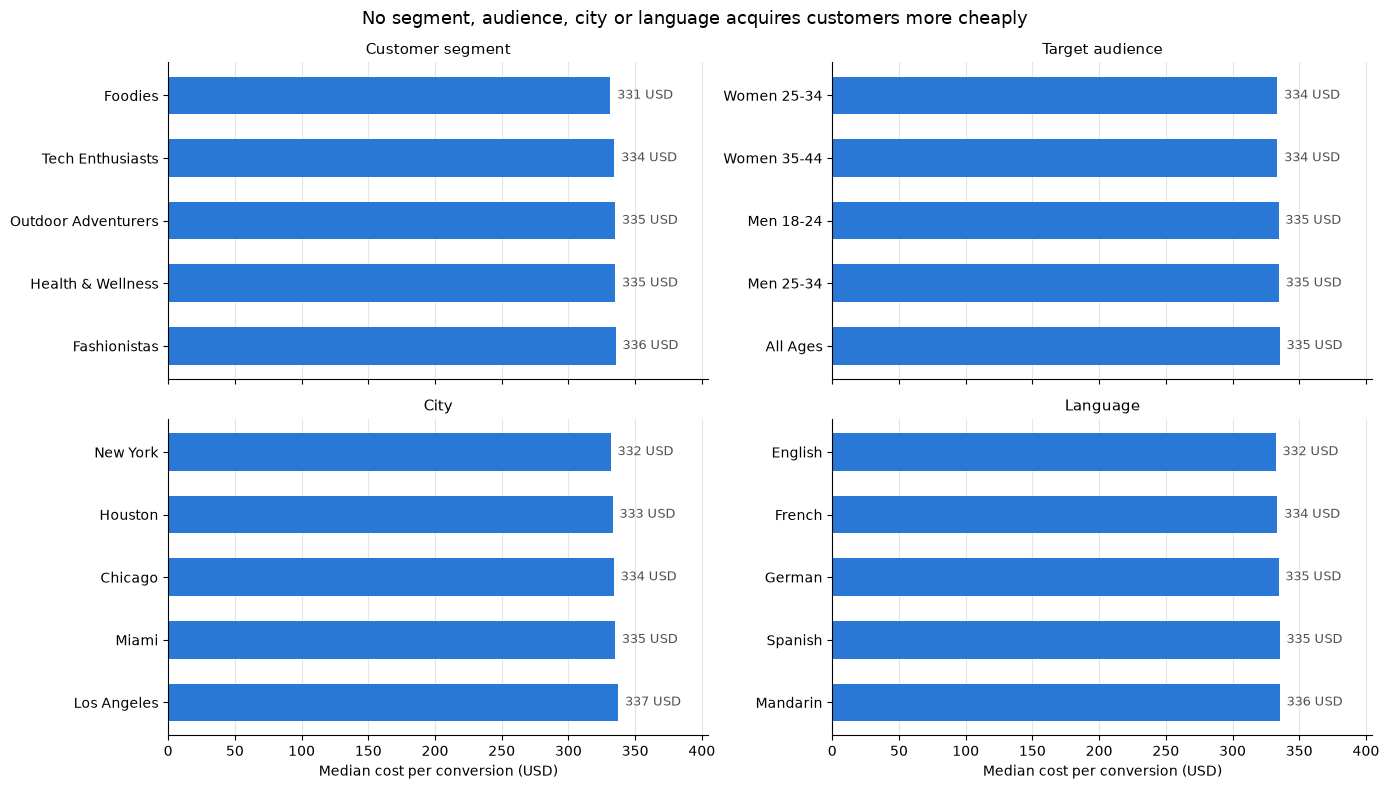

In [32]:
# Small multiples: median cost per conversion per group, one panel per dimension, same x-axis
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
x_max = audience_summary["Cost_per_Conversion"].max() * 1.2

for ax, (dimension, label) in zip(axes.flat, dimensions.items()):
    # Horizontal bars draw the first item at the bottom: sort descending to put the cheapest on top
    medians = audience_summary.loc[dimension, "Cost_per_Conversion"].sort_values(ascending=False)
    ax.barh(medians.index, medians, color=BLUE, height=0.6)
    for y, value in enumerate(medians):
        ax.text(value + 5, y, f"{value:,.0f} USD", va="center", color=GRAY, fontsize=9)
    ax.set_xlim(0, x_max)
    ax.set_title(label, fontsize=11)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("Median cost per conversion (USD)")

fig.suptitle("No segment, audience, city or language acquires customers more cheaply", fontsize=13)
plt.tight_layout()
fig.savefig("../reports/figures/q3_audiences_cost_per_conversion.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
# Cross two dimensions with pivot_table: median cost per conversion for each segment x audience pair
segment_audience = pd.pivot_table(
    df_clean, values="Cost_per_Conversion",
    index="Customer_Segment", columns="Target_Audience", aggfunc="median",
)
print(f"25 segment x audience pairs: median cost per conversion from "
      f"{segment_audience.min().min():,.1f} to {segment_audience.max().max():,.1f} USD")
print(f"Campaigns per pair: {df_clean.groupby(['Customer_Segment', 'Target_Audience']).size().min():,} "
      f"to {df_clean.groupby(['Customer_Segment', 'Target_Audience']).size().max():,}")
segment_audience.round(1)

25 segment x audience pairs: median cost per conversion from 324.7 to 346.4 USD
Campaigns per pair: 7,852 to 8,175


Target_Audience,All Ages,Men 18-24,Men 25-34,Women 25-34,Women 35-44
Customer_Segment,,,,,
Fashionistas,332.2,337.6,339.4,334.3,336.2
Foodies,332.7,324.7,331.6,334.9,334.8
Health & Wellness,332.3,343.5,335.4,328.6,334.7
Outdoor Adventurers,346.4,330.5,331.2,334.1,333.3
Tech Enthusiasts,333.4,335.3,338.4,336.0,329.5


**Answer to question 3: no segment, audience, city or language responds better than the others.**

- **Every group pays almost the same per customer.** Within each dimension, median cost per conversion stays in a range of 4 to 6 USD: segments from 331.5 (Foodies) to 335.5 USD (Fashionistas), audiences from 333.6 (Women 25-34) to 335.5 USD (All Ages), cities from 331.8 (New York) to 337.4 USD (Los Angeles) and languages from 332.4 (English) to 335.5 USD (Mandarin). CTR is about 10% and conversion rate 8% in all 20 groups, mean engagement goes from 5.47 to 5.52, and the share of high-cost campaigns from 9.0% to 9.4%.
- **The tests confirm it.** Only 1 of the 20 tests is below 0.05: ROI by target audience (p = 0.037). This is the single false positive expected by chance across 20 tests: it does not survive the Bonferroni correction (threshold 0.0025), its effect size is practically 0 (0.000031), and the audience medians it compares are 4.99 to 5.02.
- **Crossing two dimensions widens the range, but only because the groups get smaller.** The `pivot_table` of segment × audience shows medians from 324.7 USD (Foodies, Men 18-24) to 346.4 USD (Outdoor Adventurers, All Ages). Each of the 25 cells has only about 8,000 campaigns (7,852 to 8,175) instead of 40,000, so random variation is larger. This is a warning for question 6: the more the data is sliced, the more extreme the "best" and "worst" groups look by pure chance, so combinations must be tested before they are trusted.

**What it means for the business:** in this data, targeting a different segment, age group, city or language does not change acquisition cost, conversion or engagement. There is no audience to prioritize or to drop on performance grounds, so targeting decisions should be driven by strategy (brand fit, market size) rather than by expected efficiency.

### 4.4 Does campaign duration affect ROI or engagement?

`Duration_days` only takes 4 values (15, 30, 45 and 60 days), so campaigns are compared as 4 groups. Besides ROI and engagement, cost per conversion, conversions and spend are included, to check whether longer campaigns cost more or get more results.

In [34]:
duration_metrics = ["ROI", "Engagement_Score", "Cost_per_Conversion", "Conversions", "Acquisition_Cost"]

duration_summary = df_clean.groupby("Duration_days").agg(
    Campaigns=("Campaign_ID", "count"),
    Median_ROI=("ROI", "median"),
    Mean_Engagement=("Engagement_Score", "mean"),
    Cost_per_Conversion=("Cost_per_Conversion", "median"),
    Conversions=("Conversions", "median"),
    Spend=("Acquisition_Cost", "median"),
    High_Cost_Share=("High_Cost_Outlier", "mean"),
)
duration_tests = compare_groups(df_clean, "Duration_days", duration_metrics)

print(duration_summary.round(3))
print()
print(duration_tests.round({"H": 2, "p_value": 3, "epsilon_squared": 6}))

               Campaigns  Median_ROI  Mean_Engagement  Cost_per_Conversion  \
Duration_days                                                                
15                 49779        5.00            5.502              335.256   
30                 50255        5.02            5.505              332.854   
45                 50100        5.00            5.490              335.035   
60                 49866        5.02            5.482              334.561   

               Conversions    Spend  High_Cost_Share  
Duration_days                                         
15                   35.76  12500.0            0.091  
30                   35.84  12504.0            0.092  
45                   35.70  12485.0            0.092  
60                   35.76  12494.5            0.094  

                        H  p_value  epsilon_squared  significant
metric                                                          
ROI                  1.89    0.596              0.0        False
Engag

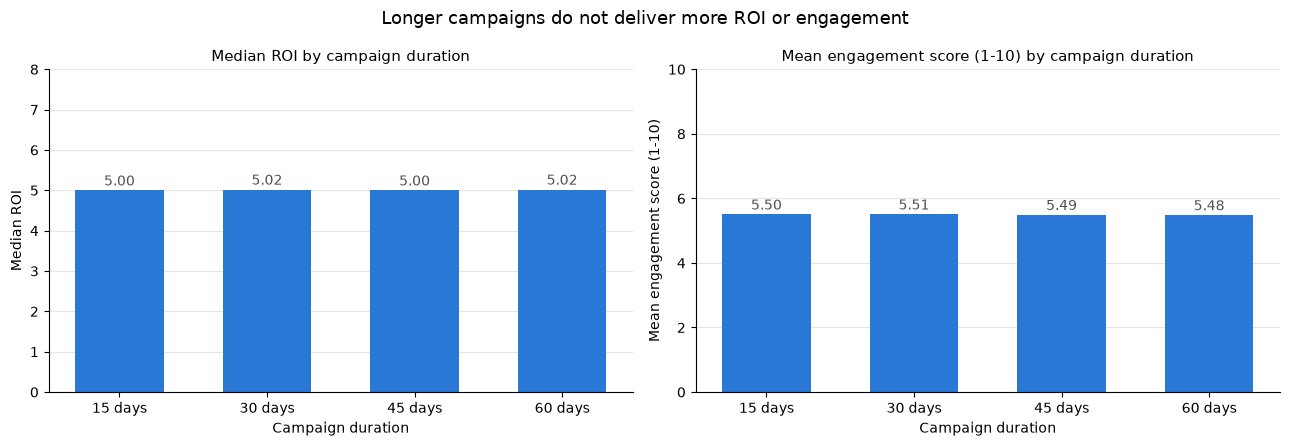

In [35]:
# Median ROI and mean engagement per duration, each on its full scale so the bars are not exaggerated
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
labels = [f"{d} days" for d in duration_summary.index]
panels = [
    (ax1, "Median_ROI", "Median ROI", (0, 8), "{:.2f}"),
    (ax2, "Mean_Engagement", "Mean engagement score (1-10)", (0, 10), "{:.2f}"),
]
for ax, column, ylabel, ylim, fmt in panels:
    values = duration_summary[column]
    ax.bar(labels, values, color=BLUE, width=0.6)
    for x, value in enumerate(values):
        ax.text(x, value + ylim[1] * 0.015, fmt.format(value), ha="center", color=GRAY, fontsize=10)
    ax.set_ylim(*ylim)
    ax.set_xlabel("Campaign duration")
    ax.set_ylabel(ylabel)
    ax.set_title(f"{ylabel} by campaign duration", fontsize=11)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.suptitle("Longer campaigns do not deliver more ROI or engagement", fontsize=13)
plt.tight_layout()
fig.savefig("../reports/figures/q4_duration_roi_engagement.png", dpi=150, bbox_inches="tight")
plt.show()

**Answer to question 4: no. Campaign duration does not change ROI, engagement or cost.**

- **The four durations perform the same.** Median ROI is 5.00 to 5.02, mean engagement 5.48 to 5.51 and median cost per conversion 332.9 to 335.3 USD, whether a campaign lasts 15 or 60 days. The share of high-cost campaigns is 9.1% to 9.4% in every group.
- **The tests confirm it**: all five p-values are between 0.53 and 0.84, with an effect size of practically 0.
- **Data quality finding:** a 60-day campaign has the same median spend (12,494.5 USD) and the same median conversions (35.76) as a 15-day campaign (12,500 USD and 35.76). In real data, running a campaign four times longer would cost more and reach more people. Here duration is just another independent random column, so it carries no information about results.

**What it means for the business:** in this data, extending a campaign does not improve its return or its engagement. Duration should be set by the campaign goal and the budget, not by an expected gain in performance.

### 4.5 Is there seasonality or a trend over time?

Section 3.4 showed that campaign dates rotate by ID, so real seasonality is not expected. It is still checked in three ways:

1. **Daily trend with a 30-day moving average.** Each day has only about 548 campaigns, so the daily value jumps a lot by chance. A **moving average** replaces each day with the mean of the 30 days around it: the random ups and downs cancel out and any real trend (a rise towards Christmas, a summer dip) becomes visible. This is the justified transformation of this section.
2. **Month, weekday and holiday comparisons** with Kruskal-Wallis, using the `Month`, `Weekday` and `Is_Holiday` columns created in section 3.
3. **Bonferroni correction** again, because 3 groupings × 3 metrics = 9 tests.

In [36]:
# One value per day, then a centered 30-day moving average to remove day-to-day noise
daily = df_clean.groupby("Date").agg(
    Cost_per_Conversion=("Cost_per_Conversion", "median"),
    Mean_Engagement=("Engagement_Score", "mean"),
    Is_Holiday=("Is_Holiday", "first"),
)
for col in ["Cost_per_Conversion", "Mean_Engagement"]:
    daily[f"{col}_MA30"] = daily[col].rolling(window=30, center=True).mean()

summary = pd.DataFrame({
    "daily_min": daily[["Cost_per_Conversion", "Mean_Engagement"]].min().values,
    "daily_max": daily[["Cost_per_Conversion", "Mean_Engagement"]].max().values,
    "moving_avg_min": daily[["Cost_per_Conversion_MA30", "Mean_Engagement_MA30"]].min().values,
    "moving_avg_max": daily[["Cost_per_Conversion_MA30", "Mean_Engagement_MA30"]].max().values,
}, index=["Median cost per conversion (USD)", "Mean engagement (1-10)"])
summary.round(2)

,daily_min,daily_max,moving_avg_min,moving_avg_max
Median cost per conversion (USD),290.10,394.64,327.88,341.37
Mean engagement (1-10),5.15,5.84,5.43,5.55


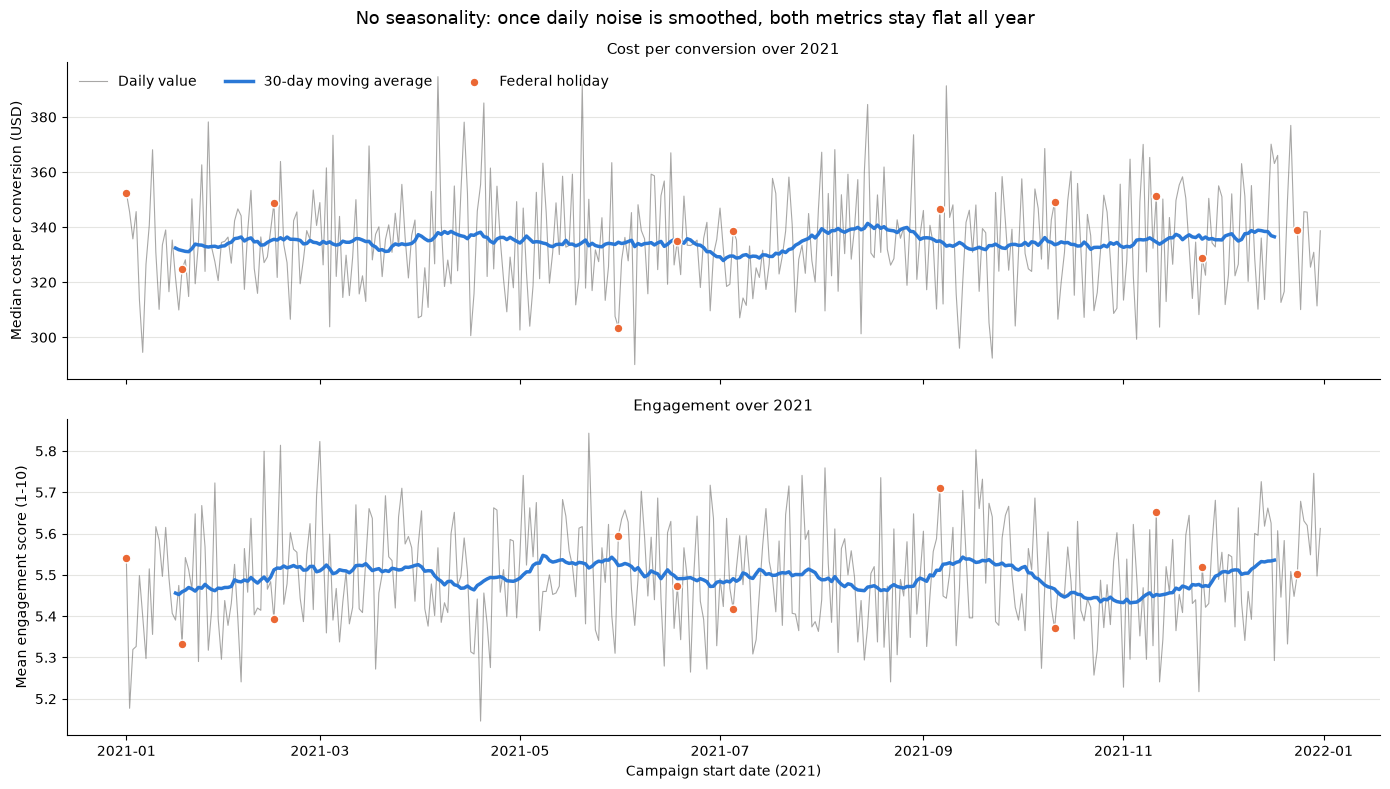

In [37]:
ORANGE = "#eb6834"   # second categorical color, used only to mark holidays

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
panels = [
    ("Cost_per_Conversion", "Median cost per conversion (USD)"),
    ("Mean_Engagement", "Mean engagement score (1-10)"),
]
holiday_days = daily[daily["Is_Holiday"]]

for ax, (col, ylabel) in zip(axes, panels):
    ax.plot(daily.index, daily[col], color=GRAY, linewidth=0.8, alpha=0.5, label="Daily value")
    ax.plot(daily.index, daily[f"{col}_MA30"], color=BLUE, linewidth=2.5, label="30-day moving average")
    ax.scatter(holiday_days.index, holiday_days[col], color=ORANGE, s=40, zorder=3,
               edgecolor="white", linewidth=1, label="Federal holiday")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].legend(loc="upper left", frameon=False, ncol=3)
axes[0].set_title("Cost per conversion over 2021", fontsize=11)
axes[1].set_title("Engagement over 2021", fontsize=11)
axes[1].set_xlabel("Campaign start date (2021)")

fig.suptitle("No seasonality: once daily noise is smoothed, both metrics stay flat all year", fontsize=13)
plt.tight_layout()
fig.savefig("../reports/figures/q5_trend_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

In [38]:
# Month, weekday and holiday vs normal day: 3 groupings x 3 metrics = 9 tests
time_metrics = ["Cost_per_Conversion", "Engagement_Score", "ROI"]
time_tests = pd.concat(
    {grouping: compare_groups(df_clean, grouping, time_metrics) for grouping in ["Month", "Weekday", "Is_Holiday"]},
    names=["Grouping", "metric"],
)
time_alpha = 0.05 / len(time_tests)
time_tests["significant_bonferroni"] = time_tests["p_value"] < time_alpha

monthly = df_clean.groupby("Month").agg(
    Cost_per_Conversion=("Cost_per_Conversion", "median"),
    Mean_Engagement=("Engagement_Score", "mean"),
    Median_ROI=("ROI", "median"),
)
holiday_vs_normal = df_clean.groupby("Is_Holiday").agg(
    Campaigns=("Campaign_ID", "count"),
    Cost_per_Conversion=("Cost_per_Conversion", "median"),
    Mean_Engagement=("Engagement_Score", "mean"),
    Median_ROI=("ROI", "median"),
)

print("By month:")
print(monthly.round(2))
print("\nHoliday vs normal day:")
print(holiday_vs_normal.round(3))
print(f"\nBonferroni threshold: 0.05 / {len(time_tests)} = {time_alpha:.4f}")
print(time_tests.round({"H": 2, "p_value": 3, "epsilon_squared": 6}))

By month:
       Cost_per_Conversion  Mean_Engagement  Median_ROI
Month                                                  
1                   332.38             5.46        5.03
2                   334.92             5.50        5.01
3                   333.71             5.52        4.99
4                   336.01             5.47        5.00
5                   333.60             5.53        5.04
6                   334.82             5.50        4.99
7                   330.51             5.50        4.97
8                   340.99             5.47        5.00
9                   331.89             5.54        5.03
10                  333.63             5.46        5.03
11                  334.72             5.46        4.99
12                  336.73             5.54        5.01

Holiday vs normal day:
            Campaigns  Cost_per_Conversion  Mean_Engagement  Median_ROI
Is_Holiday                                                             
False          193973              334

**Answer to question 5: no. There is no seasonality, weekly pattern, holiday effect or trend over 2021.**

- **The moving average is flat.** Daily median cost per conversion jumps between 290.1 and 394.6 USD, but the 30-day moving average only moves between 327.9 and 341.4 USD, with no rise or fall at any time of the year. Daily mean engagement ranges from 5.15 to 5.84, while its moving average stays between 5.43 and 5.55. The daily jumps are noise from having only about 548 campaigns per day.
- **Months, weekdays and holidays behave the same.** Monthly median cost per conversion goes from 330.5 (July) to 341.0 USD (August) without any seasonal shape, and campaigns that start on a federal holiday are no different from the rest (cost per conversion 339.1 vs 334.3 USD, p = 0.688).
- **One test is below 0.05, but it is noise again.** Engagement by month gives p = 0.021, yet the monthly means only go from 5.46 to 5.54 on a 1-10 scale, the effect size is practically 0, and the result does not pass the Bonferroni threshold for 9 tests (0.0056).
- **This was expected**: section 3.4 showed that campaign dates follow the campaign ID in a fixed 365-day rotation, so the date carries no business information.

**What it means for the business:** this dataset cannot say *when* to invest. Real seasonality (Black Friday, holidays, summer) is one of the biggest levers in advertising, so measuring it would need data with real campaign dates. This is one of the data gaps listed in the conclusions.

### 4.6 Which combinations work best, and where is budget wasted?

This question has two parts:

1. **Combinations.** Channel × campaign type × target audience gives 6 × 5 × 5 = **150 combinations**, with about 1,200 to 1,500 campaigns each. Section 4.3 warned that slicing the data into small groups makes the "best" and "worst" look more extreme by chance. Two checks separate real winners from noise: the Kruskal-Wallis test, and a **split-half check**. The campaigns are split at random into two halves, the combinations are ranked in each half, and the two rankings are compared. A real winner would rank near the top in both halves; a lucky one would not.
2. **Budget waste.** Instead of looking for a bad channel or audience, this part looks at individual campaigns: how much budget goes to the least efficient ones and how many conversions it brings back.

In [39]:
import numpy as np

combo_keys = ["Channel_Used", "Campaign_Type", "Target_Audience"]
df_clean["Combination"] = df_clean[combo_keys].agg(" | ".join, axis=1)

combos = df_clean.groupby("Combination").agg(
    Campaigns=("Campaign_ID", "count"),
    Cost_per_Conversion=("Cost_per_Conversion", "median"),
    High_Cost_Share=("High_Cost_Outlier", "mean"),
    Spend=("Acquisition_Cost", "sum"),
    Conversions=("Conversions", "sum"),
).sort_values("Cost_per_Conversion")

print(f"{len(combos)} combinations, {combos['Campaigns'].min():,} to {combos['Campaigns'].max():,} campaigns each")
print(f"Median cost per conversion: {combos['Cost_per_Conversion'].min():.1f} to {combos['Cost_per_Conversion'].max():.1f} USD")
print(compare_groups(df_clean, "Combination", ["Cost_per_Conversion"]).round({"H": 2, "p_value": 3, "epsilon_squared": 6}))

# Split-half check: rank the combinations in two random halves and compare the rankings
rng = np.random.default_rng(42)
in_half_a = rng.random(len(df_clean)) < 0.5
half_a = df_clean[in_half_a].groupby("Combination")["Cost_per_Conversion"].median()
half_b = df_clean[~in_half_a].groupby("Combination")["Cost_per_Conversion"].median()
top10_a, top10_b = set(half_a.nsmallest(10).index), set(half_b.nsmallest(10).index)

print(f"\nSpearman correlation between the two half rankings: {half_a.corr(half_b, method='spearman'):.3f}")
print(f"Combinations in the top 10 of both halves: {len(top10_a & top10_b)} of 10")

print("\nApparent best and worst 5 combinations (full data):")
pd.concat([combos.head(5), combos.tail(5)])[["Campaigns", "Cost_per_Conversion", "High_Cost_Share"]].round(3)

150 combinations, 1,201 to 1,459 campaigns each
Median cost per conversion: 310.6 to 366.4 USD
                          H  p_value  epsilon_squared  significant
metric                                                            
Cost_per_Conversion  126.21    0.912              0.0        False

Spearman correlation between the two half rankings: -0.047
Combinations in the top 10 of both halves: 0 of 10

Apparent best and worst 5 combinations (full data):


,Campaigns,Cost_per_Conversion,High_Cost_Share
Combination,,,
Website | Influencer | Men 25-34,1390,310.555,0.085
Website | Search | All Ages,1390,313.201,0.086
Instagram | Social Media | Men 18-24,1342,313.378,0.082
Facebook | Email | Men 18-24,1337,314.418,0.093
Facebook | Social Media | Men 18-24,1358,315.177,0.068
Google Ads | Social Media | Men 18-24,1269,353.019,0.102
Google Ads | Email | All Ages,1315,355.785,0.098
Instagram | Display | Men 25-34,1359,356.376,0.092
Facebook | Influencer | Women 35-44,1201,360.224,0.093


**What the combination check tells us:** the full ranking makes it look as if *Website | Influencer | Men 25-34* (310.6 USD) beats *YouTube | Search | Men 18-24* (366.4 USD) by 56 USD per customer. It does not survive either check. The Kruskal-Wallis test across the 150 combinations gives p = 0.912, and the split-half check shows that the ranking does not repeat: the correlation between the two halves is −0.047 and **none of the 10 best combinations in one half is among the 10 best in the other**. Picking the "winning" combination from this table would be picking noise.

**Data quality check: do channel and campaign type make sense together?** Some combinations above are odd for real marketing, such as *Facebook | Email*, *Google Ads | Social Media* or *YouTube | Search*: an email campaign is not run on Facebook. The cross-table below counts the campaigns for every channel × campaign type pair, and a **chi-square test of independence** checks whether the two columns are related. The test compares the observed counts with the counts expected if channel and campaign type had no relationship at all; a high p-value means the pairs are spread as if assigned at random.

In [40]:
from scipy.stats import chi2_contingency

channel_by_type = pd.crosstab(df_clean["Channel_Used"], df_clean["Campaign_Type"])
chi2, chi2_p, dof, _ = chi2_contingency(channel_by_type)

print(f"Channel x campaign type pairs with campaigns: {(channel_by_type > 0).sum().sum()} of {channel_by_type.size}")
print(f"Campaigns per pair: {channel_by_type.values.min():,} to {channel_by_type.values.max():,}")
print(f"Chi-square test of independence: chi2 = {chi2:.2f}, p = {chi2_p:.3f} ({dof} degrees of freedom)")
channel_by_type

Channel x campaign type pairs with campaigns: 30 of 30
Campaigns per pair: 6,488 to 6,899
Chi-square test of independence: chi2 = 17.36, p = 0.629 (20 degrees of freedom)


Campaign_Type,Display,Email,Influencer,Search,Social Media
Channel_Used,,,,,
Email,6701,6760,6698,6718,6722
Facebook,6628,6589,6548,6488,6566
Google Ads,6590,6689,6764,6720,6675
Instagram,6724,6640,6736,6623,6669
Website,6622,6611,6650,6899,6578
YouTube,6722,6581,6773,6709,6607


**What the cross-table tells us:** all 30 channel × campaign type pairs exist, each with between 6,488 and 6,899 campaigns, including combinations that make no business sense (6,589 *Email* campaigns run on *Facebook*). The only logical pair, *Email* campaigns on the *Email* channel, is no more frequent than the others (6,760). The chi-square test gives p = 0.629: channel and campaign type are **independent**. Together with the near-zero correlations in section 4.2, this confirms that **the columns of this dataset were generated at random and separately from each other**. It explains why no combination, segment or channel stands out: there is no real structure in the data for the analysis to find.

In [41]:
import plotly.express as px

# Interactive view of the 150 combinations: hover to see each one, zoom to compare.
# GitHub does not render Plotly, so the chart is also saved as a standalone HTML file.
plot_data = combos.reset_index().assign(
    Spend_M=lambda d: d["Spend"] / 1e6,
    High_Cost_Pct=lambda d: d["High_Cost_Share"] * 100,
)
fig = px.scatter(
    plot_data, x="Cost_per_Conversion", y="High_Cost_Pct", size="Spend_M",
    hover_name="Combination",
    hover_data={"Campaigns": ":,", "Cost_per_Conversion": ":.1f", "High_Cost_Pct": ":.1f", "Spend_M": ":.1f"},
    labels={
        "Cost_per_Conversion": "Median cost per conversion (USD)",
        "High_Cost_Pct": "High-cost campaigns (% of the combination)",
        "Spend_M": "Total spend (million USD)",
    },
    title="150 channel x campaign type x audience combinations: one tight cluster, no clear winner",
    color_discrete_sequence=[BLUE],
)
fig.update_traces(marker={"opacity": 0.7, "line": {"width": 1, "color": "white"}})
fig.update_layout(template="simple_white", height=500)
fig.write_html("../reports/figures/q6_combinations_interactive.html", include_plotlyjs="cdn")
fig.show()

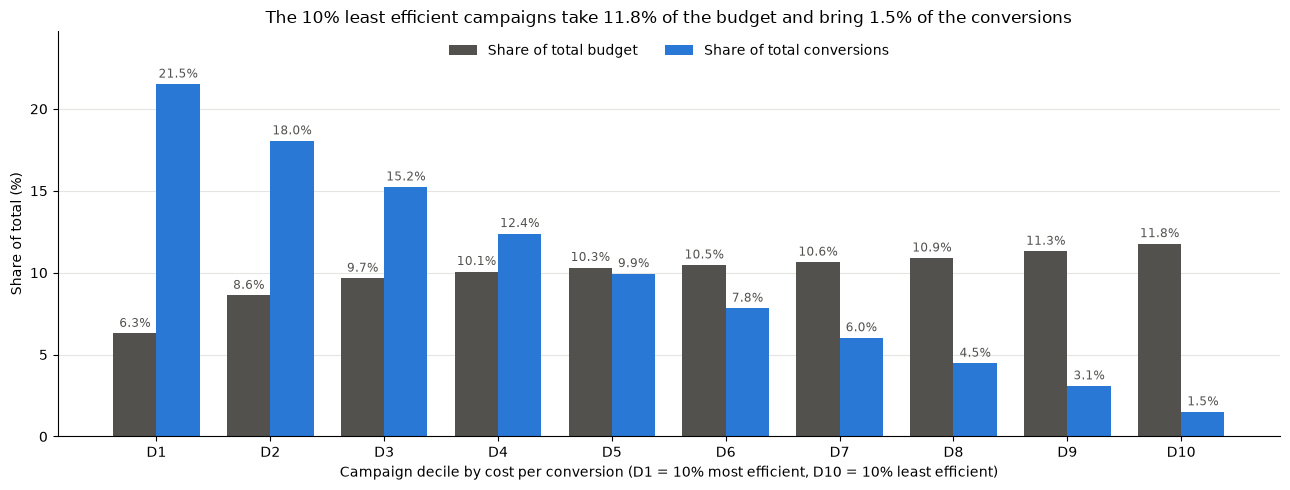

,Spend_Share,Conversion_Share
Decile (1 = cheapest per conversion),,
1,6.3,21.5
2,8.6,18.0
3,9.7,15.2
4,10.1,12.4
5,10.3,9.9
6,10.5,7.8
7,10.6,6.0
8,10.9,4.5
9,11.3,3.1


In [42]:
# Budget waste at campaign level: split campaigns into 10 equal groups (deciles) by cost per conversion
total_spend = df_clean["Acquisition_Cost"].sum()
total_conversions = df_clean["Conversions"].sum()

decile = pd.qcut(df_clean["Cost_per_Conversion"], 10, labels=range(1, 11))
deciles = df_clean.groupby(decile, observed=True).agg(
    Spend=("Acquisition_Cost", "sum"), Conversions=("Conversions", "sum"),
)
deciles["Spend_Share"] = deciles["Spend"] / total_spend * 100
deciles["Conversion_Share"] = deciles["Conversions"] / total_conversions * 100
deciles.index.name = "Decile (1 = cheapest per conversion)"

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(deciles))
width = 0.38
ax.bar(x - width / 2, deciles["Spend_Share"], width, color=GRAY, label="Share of total budget")
ax.bar(x + width / 2, deciles["Conversion_Share"], width, color=BLUE, label="Share of total conversions")
for i, (s, c) in enumerate(zip(deciles["Spend_Share"], deciles["Conversion_Share"])):
    ax.text(i - width / 2, s + 0.4, f"{s:.1f}%", ha="center", color=GRAY, fontsize=8.5)
    ax.text(i + width / 2, c + 0.4, f"{c:.1f}%", ha="center", color=GRAY, fontsize=8.5)
ax.set_xticks(x, [f"D{d}" for d in deciles.index])
ax.set_xlabel("Campaign decile by cost per conversion (D1 = 10% most efficient, D10 = 10% least efficient)")
ax.set_ylabel("Share of total (%)")
ax.set_ylim(0, deciles[["Spend_Share", "Conversion_Share"]].max().max() * 1.15)
ax.legend(frameon=False, loc="upper center", ncol=2)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_title("The 10% least efficient campaigns take 11.8% of the budget and bring 1.5% of the conversions", fontsize=12)
plt.tight_layout()
fig.savefig("../reports/figures/q6_budget_vs_conversions_by_decile.png", dpi=150, bbox_inches="tight")
plt.show()

deciles[["Spend_Share", "Conversion_Share"]].round(1)

In [43]:
# The high-cost campaigns flagged in section 3.3: budget, results and a what-if scenario
high = df_clean["High_Cost_Outlier"]
high_spend = df_clean.loc[high, "Acquisition_Cost"].sum()
high_conversions = df_clean.loc[high, "Conversions"].sum()
normal_cost = df_clean.loc[~high, "Acquisition_Cost"].sum() / df_clean.loc[~high, "Conversions"].sum()
high_cost = high_spend / high_conversions

# What-if: the same budget converting at the average cost of the normal campaigns
extra_conversions = high_spend / normal_cost - high_conversions

print(f"High-cost campaigns: {high.mean():.1%} of campaigns, {high_spend / total_spend:.1%} of budget "
      f"({high_spend / 1e6:,.1f} of {total_spend / 1e6:,.1f} million USD), {high_conversions / total_conversions:.1%} of conversions")
print(f"Average cost per conversion: {high_cost:,.1f} USD (high-cost) vs {normal_cost:,.1f} USD (normal)")
print(f"What-if extra conversions: {extra_conversions:,.0f} ({extra_conversions / total_conversions:.1%} of all conversions)")

# Early warning: how well does a low conversion rate catch the high-cost campaigns?
rows = []
for threshold in [0.01, 0.02, 0.03]:
    flagged = df_clean["Conversion_Rate"] <= threshold
    rows.append({
        "Rule": f"Conversion rate <= {threshold:.0%}",
        "Campaigns_Flagged_%": flagged.mean() * 100,
        "High_Cost_Caught_%": (flagged & high).sum() / high.sum() * 100,
        "Flagged_That_Are_High_Cost_%": (flagged & high).sum() / flagged.sum() * 100,
    })
pd.DataFrame(rows).set_index("Rule").round(1)

High-cost campaigns: 9.2% of campaigns, 10.9% of budget (272.1 of 2,500.9 million USD), 1.3% of conversions
Average cost per conversion: 2,336.0 USD (high-cost) vs 256.5 USD (normal)
What-if extra conversions: 944,025 (10.7% of all conversions)


,Campaigns_Flagged_%,High_Cost_Caught_%,Flagged_That_Are_High_Cost_%
Rule,,,
Conversion rate <= 1%,3.5,29.4,77.2
Conversion rate <= 2%,10.7,58.4,50.3
Conversion rate <= 3%,17.8,73.9,38.3


**Answer to question 6: no combination works reliably better, but budget is clearly wasted on individual campaigns that convert poorly.**

- **No winning combination.** The 150 channel × campaign type × audience combinations range from 310.6 to 366.4 USD per conversion, but the gap is noise: p = 0.912, and the ranking does not repeat between two random halves of the data (0 of the top 10 in common, correlation −0.047). The interactive chart shows the 150 combinations as one tight cluster.
- **The waste is at campaign level.** Ranking campaigns by cost per conversion, the **10% least efficient take 11.8% of the budget and bring only 1.5% of the conversions**, while the 10% most efficient take 6.3% of the budget and bring 21.5%. This staircase shape appears whenever campaigns are sorted by efficiency, so the shape itself is not the finding: what matters is the **size of the gap** (the last decile gets almost 8 times less than its share of the budget) and the fact, shown in sections 4.1 to 4.5, that none of the targeting choices predicts which campaigns end up in it.
- **The high-cost campaigns from section 3.3** are 9.2% of campaigns but take **10.9% of the budget (272.1 of 2,500.9 million USD) for 1.3% of the conversions**. They pay on average 2,336.0 USD per conversion, against 256.5 USD for the rest.
- **What-if scenario:** if that budget had converted at the average cost of the normal campaigns, it would have brought about **944,000 more conversions (+10.7%)**. This is an upper bound: it assumes the money could be moved to campaigns that keep the same efficiency, which real budgets rarely do.
- **An early warning signal exists, but only after launch.** None of the targeting choices predicts which campaign will be expensive (sections 4.1 to 4.5), but its results do: a conversion rate of 2% or less flags 10.7% of campaigns and catches 58.4% of the high-cost ones (half of the flagged campaigns are high-cost).

**What it means for the business:** the budget lever is not *where* or *to whom* to advertise, but **which running campaigns to stop**. Monitoring conversion rate early and pausing campaigns that stay at 2% or below would cut most of the waste.

## 5. Conclusions and recommendations

### 5.1 Answers to the key questions

| # | Question | Answer | Evidence |
|---|---|---|---|
| 1 | Which channels acquire customers most efficiently? | **None stands out.** | Median cost per conversion 330.5 to 337.3 USD across the 6 channels; all 7 metrics p = 0.17 to 0.93 (section 4.1). |
| 2 | Do more spend or more impressions lead to more engagement? | **No.** | Mean engagement 5.48 to 5.52 in every spend and impression quintile (p = 0.337 and 0.438); Spearman correlations −0.003 to 0.003 (section 4.2). |
| 3 | Which segments, audiences, cities and languages respond best? | **None.** | Cost per conversion 331.5 to 337.4 USD in all 20 groups; 0 of 20 tests significant after Bonferroni (section 4.3). |
| 4 | Does campaign duration affect ROI or engagement? | **No.** | Median ROI 5.00 to 5.02 and mean engagement 5.48 to 5.51 for 15 to 60 days; p = 0.53 to 0.84 (section 4.4). |
| 5 | Is there seasonality or a trend over time? | **No.** | 30-day moving average of cost per conversion stays between 327.9 and 341.4 USD all year; holidays p = 0.688 (section 4.5). |
| 6 | Which combinations work best, and which waste budget? | **No combination wins reliably; budget is wasted on individual campaigns.** | 0 of the top 10 combinations repeat between two random halves; the 10% least efficient campaigns take 11.8% of the budget for 1.5% of the conversions (section 4.6). |

### 5.2 Three key messages

**1. Channel, audience, location, language, spend, duration and timing are not levers in this data.** Every comparison was tested and none shows a real difference. A ranking table will always show a "best" and a "worst" group, but the split-half check in section 4.6 proves those rankings are chance.

**2. The real lever is stopping the campaigns that do not convert.** The 9.2% of campaigns flagged as high-cost take 10.9% of the budget (272.1 of 2,500.9 million USD) and bring only 1.3% of the conversions, paying 2,336.0 USD per conversion against 256.5 USD for the rest. They cannot be predicted from how a campaign is set up, but they can be spotted from their early results: a conversion rate of 2% or less catches 58.4% of them.

**3. Better data is needed before taking channel or timing decisions.** The dataset has no retention data, its ROI does not reflect costs and its dates are not real, so it cannot answer *where*, *when* or *for how long* to advertise (see the data quality report in section 5.4).

### 5.3 Recommendations

1. **Monitor conversion rate from the first days of every campaign and review those at 2% or below.** In this data that rule flags 10.7% of campaigns, and half of them are high-cost ones. A stricter rule (1% or below) flags fewer campaigns (3.5%) with higher precision (77.2%), so the threshold can be adjusted to the review capacity of the team.
2. **Do not move budget between channels, audiences or cities based on this data.** The differences are noise and would not repeat. Targeting should follow strategy (brand fit, market size, partner priorities) rather than expected efficiency.
3. **Measure what matters for content partners.** For streaming, CTV, gaming and content apps, the business value of a campaign is how long acquired users stay. The next dataset should include **retention** (for example day-7 and day-30 active users), a **consistent ROI** calculated from spend and revenue, **real campaign dates** to capture seasonality, and **controlled tests** (A/B tests) to measure the real effect of a channel or a creative.
4. **Treat the absolute values with caution.** The median CTR of 10% and CPM of 2,270 USD are far from real advertising benchmarks, so the figures in this notebook describe relative patterns, not expected real-world costs.

### 5.4 Data quality report

**What was wrong or missing, and how it was handled:**

| Issue | Where it was found | Decision |
|---|---|---|
| `Acquisition_Cost` stored as text (`"$16,174.00"`) | Section 2 | **Corrected**: converted to float (USD) |
| `Duration` stored as text (`"30 days"`) | Section 2 | **Corrected**: converted to integer `Duration_days` |
| `Date` stored as text | Section 2 | **Corrected**: converted to datetime |
| Two columns without a definition (`Conversion_Rate`, `Acquisition_Cost`) | Section 3.2 | **Assumed**: conversions / clicks, and total campaign spend in USD |
| High cost-per-conversion campaigns (9.2%) | Section 3.3 | **Kept and flagged** (`High_Cost_Outlier`), because they are the budget waste |
| No date or holiday context | Section 3.4 | **Enriched** with federal holidays from the Nager.Date API |
| Missing values, duplicates, inconsistent labels, clicks above impressions | Section 2 | **None found** |

**What remains as a limitation (cannot be fixed with this dataset):**

- **Columns are independent of each other.** Correlations between the original columns are −0.01 to 0.01 (section 4.2) and channel and campaign type are independent (chi-square p = 0.629), including combinations that make no business sense (6,589 email campaigns run on Facebook). The data was generated at random, column by column.
- **Evenly spread values.** The original columns are uniform, with no outliers, and `Engagement_Score` has about 20,000 campaigns on each value from 1 to 10.
- **Unrealistic scale.** Median CTR is 10.0% and median CPM 2,270 USD, far above real advertising values.
- **`ROI` is not consistent with costs.** Campaigns paying about 7 times more per conversion have the same median ROI (5.00 vs 5.01).
- **Duration does not affect spend.** A 60-day campaign has the same median spend as a 15-day one (12,494.5 vs 12,500 USD).
- **Dates are not real.** They follow the campaign ID in a fixed 365-day rotation (100% of rows), so seasonality cannot be measured.
- **No retention data.** `Engagement_Score` is the closest proxy, and it does not respond to any campaign setting.

**What is still pending:** a dataset with real campaign dates, retention metrics and a documented ROI definition, to repeat this analysis where differences can actually exist. The cleaning, testing and pipeline code in `src/` can be reused as it is.